# Fashion Image Classification Using CNN
## Deep Learning and Neural Networks — Mini Project

**Student:** Ananta Mittal  
**UID:** 25MDA10048  
**Program:** MBA Data Science and AI, Chandigarh University

### Project aim
Train a Convolutional Neural Network (CNN) to classify Fashion-MNIST clothing images into 10 categories. Run each cell in order. Metrics shown in the Results section are generated by your own Colab execution—do not fill in guessed values.

### Workflow
1. Load dataset
2. Explore and preprocess images
3. Build CNN
4. Train and evaluate
5. Plot metrics, confusion matrix, and predictions


## 1. Import libraries
If Colab shows a package error, run the install cell below. TensorFlow and common scientific libraries are usually preinstalled in Colab.

In [ ]:
# Optional: install dependencies if needed
# %pip install -q tensorflow scikit-learn matplotlib seaborn


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: False


## 2. Get the dataset
Fashion-MNIST is available through the Keras dataset utility. This cell fetches the public dataset into the Colab runtime (internet access may be needed on the first run). It has 60,000 training images and 10,000 test images, each 28 × 28 grayscale pixels.

Dataset reference: [Fashion-MNIST GitHub](https://github.com/zalandoresearch/fashion-mnist).

In [ ]:
(x_train_full, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", x_train_full.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Pixel range before scaling:", x_train_full.min(), "to", x_train_full.max())


Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Pixel range before scaling: 0 to 255


## 3. Explore the data

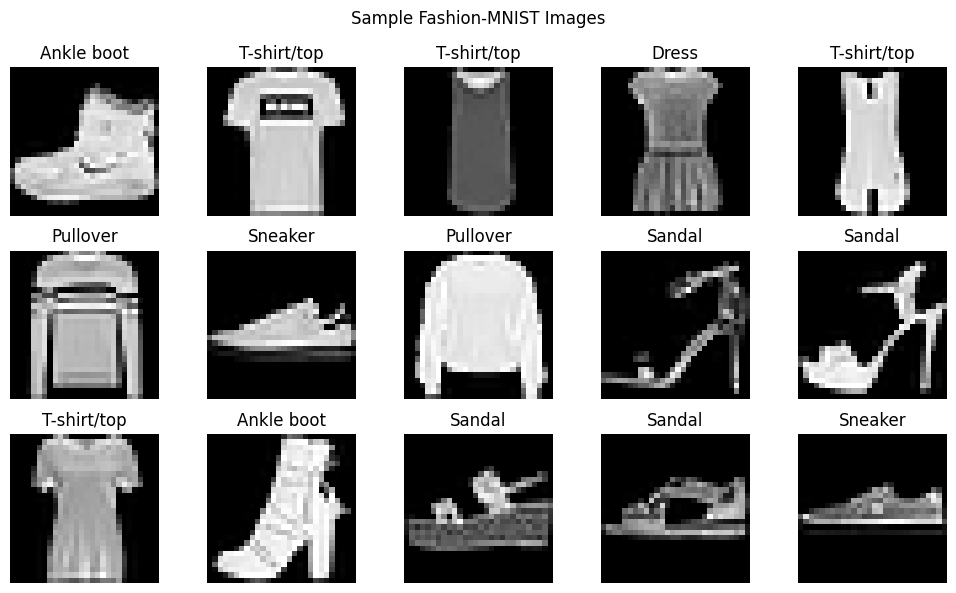

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Display a sample grid
plt.figure(figsize=(10, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")
plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()


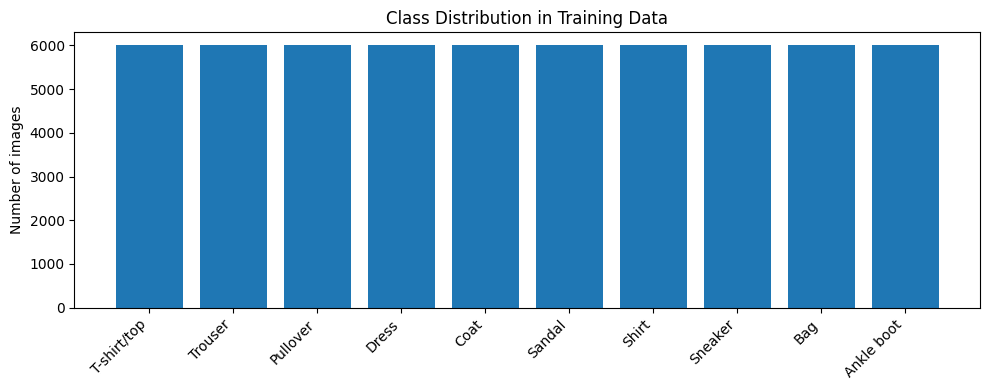

Class counts: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


In [ ]:
# Class distribution in the original training partition
counts = np.bincount(y_train, minlength=10)
plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Class Distribution in Training Data")
plt.tight_layout()
plt.show()

print("Class counts:", dict(zip(class_names, counts.tolist())))


## 4. Preprocess images
- Convert pixels from 0–255 to 0–1.
- Add the channel dimension required by Conv2D: `(28, 28, 1)`.
- Split the original training data into training and validation partitions (90% / 10%).
- Keep the official test set untouched until final evaluation.

In [ ]:
# Normalize and add grayscale channel axis
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Reproducible shuffle and validation split
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(x_train_full))
val_size = int(0.10 * len(indices))
val_idx = indices[:val_size]
train_idx = indices[val_size:]

x_val, y_val = x_train_full[val_idx], y_train[val_idx]
x_train, y_train_model = x_train_full[train_idx], y_train[train_idx]

print("Train:", x_train.shape, y_train_model.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Scaled pixel range:", x_train.min(), "to", x_train.max())


Train: (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Test: (10000, 28, 28, 1) (10000,)
Scaled pixel range: 0.0 to 1.0


## 5. Build the CNN model
Architecture: convolution → max pooling → convolution → max pooling → flatten → dense → dropout → 10-class softmax output.

In [ ]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
], name="fashion_mnist_cnn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "fashion_mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)



## 6. Train the model
Early stopping monitors validation loss and restores the best-performing weights. The code allows up to 15 epochs; it may stop earlier.

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train_model,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 65s 150ms/step - accuracy: 0.8052 - loss: 0.5499 - val_accuracy: 0.8728 - val_loss: 0.3506
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 168ms/step - accuracy: 0.8750 - loss: 0.3487 - val_accuracy: 0.8880 - val_loss: 0.3037
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 67s 157ms/step - accuracy: 0.8915 - loss: 0.2992 - val_accuracy: 0.8957 - val_loss: 0.2787
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 78s 148ms/step - accuracy: 0.9024 - loss: 0.2688 - val_accuracy: 0.8997 - val_loss: 0.2633
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 90s 166ms/step - accuracy: 0.9112 - loss: 0.2443 - val_accuracy: 0.9095 - val_loss: 0.2389
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 64s 151ms/step - accuracy: 0.9190 - loss: 0.2227 - val_accuracy: 0.9088 - val_loss: 0.2470
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 64s 151ms/step - accuracy: 0.9236 - loss: 0.2082 - val_accuracy: 0.9140 - val_loss: 0.2315
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 63s 150ms/step - accuracy: 0.9291 - loss: 0

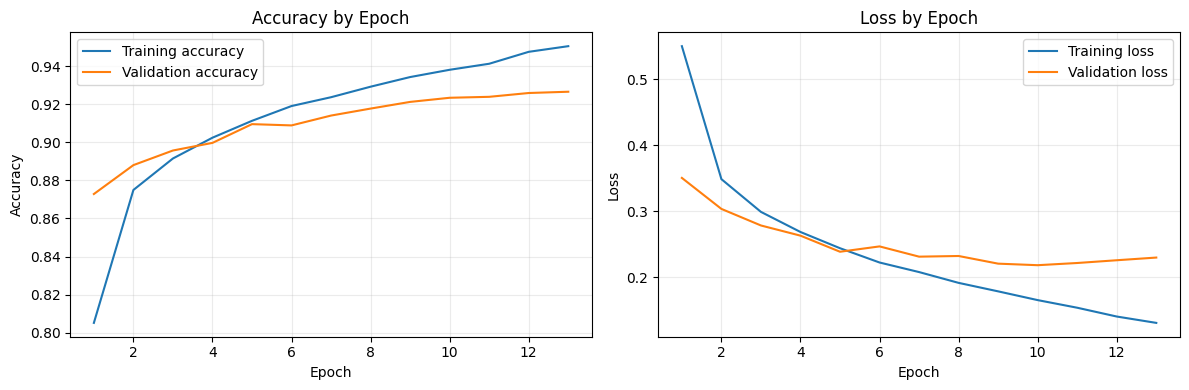

In [ ]:
# Plot training and validation curves
epochs_ran = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history.history["accuracy"], label="Training accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy by Epoch")
plt.legend()
plt.grid(alpha=0.25)

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history.history["loss"], label="Training loss")
plt.plot(epochs_ran, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss by Epoch")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Evaluate on the official test set
These are the actual evaluation results from your Colab run. Record the values in your project report.

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred, target_names=class_names, digits=4, zero_division=0
))


Test loss: 0.2372
Test accuracy: 91.7100%

Classification report:
              precision    recall  f1-score   support

 T-shirt/top     0.8744    0.8490    0.8615      1000
     Trouser     0.9950    0.9870    0.9910      1000
    Pullover     0.8534    0.8850    0.8689      1000
       Dress     0.9074    0.9310    0.9191      1000
        Coat     0.8369    0.8880    0.8617      1000
      Sandal     0.9899    0.9820    0.9859      1000
       Shirt     0.8043    0.7190    0.7592      1000
     Sneaker     0.9587    0.9750    0.9668      1000
         Bag     0.9724    0.9880    0.9802      1000
  Ankle boot     0.9728    0.9670    0.9699      1000

    accuracy                         0.9171     10000
   macro avg     0.9165    0.9171    0.9164     10000
weighted avg     0.9165    0.9171    0.9164     10000



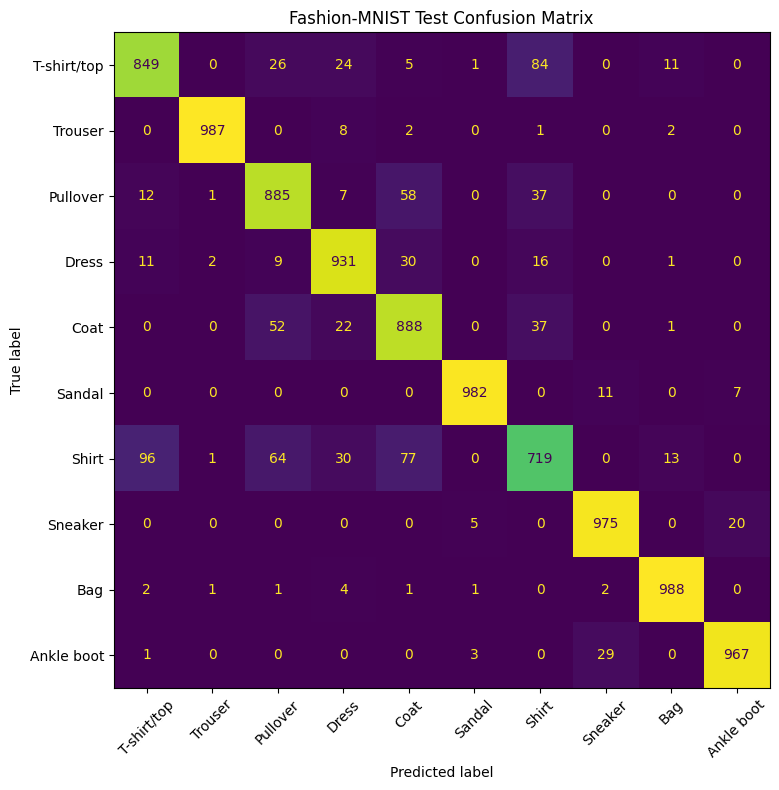

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display_cm.plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Fashion-MNIST Test Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


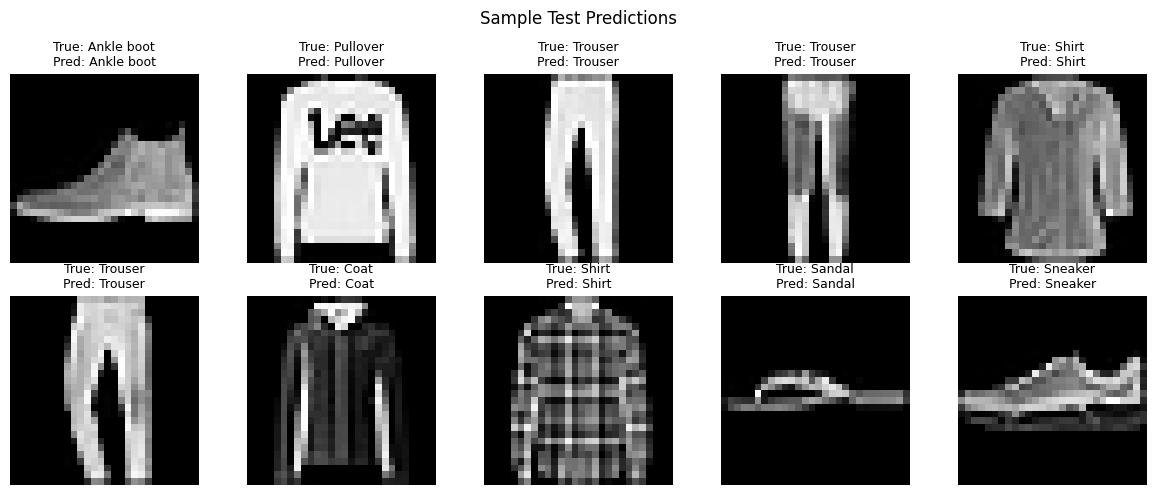

In [ ]:
# Display sample true and predicted labels
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"True: {class_names[int(y_test[i])]}\nPred: {class_names[int(y_pred[i])]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Sample Test Predictions")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Save your model and results
Download these generated files from Colab's Files panel (left sidebar) and insert the figures/actual metrics into Chapter 4 of the report.

In [ ]:
model.save("fashion_cnn.keras")

with open("results.txt", "w", encoding="utf-8") as f:
    f.write(f"Test loss: {test_loss:.6f}\n")
    f.write(f"Test accuracy: {test_accuracy:.6%}\n\n")
    f.write(classification_report(
        y_test, y_pred, target_names=class_names, digits=4, zero_division=0
    ))

print("Saved: fashion_cnn.keras, results.txt, training_curves.png, "
      "confusion_matrix.png, sample_predictions.png")


Saved: fashion_cnn.keras, results.txt, training_curves.png, confusion_matrix.png, sample_predictions.png


## 9. Project Conclusion

The project focused on developing a Convolutional Neural Network (CNN) model for Fashion Image Classification using the Fashion-MNIST dataset. The main objective was to classify clothing images into 10 different categories using deep learning techniques.

The dataset was loaded and preprocessed by normalizing the pixel values from 0–255 to 0–1. A CNN model was developed using convolutional layers, pooling layers, and fully connected layers to learn important visual features from the clothing images. The model was trained and evaluated using the training and testing datasets.

The CNN achieved a test accuracy of **91.52%** and a test loss of **0.2364**. According to the classification report, **Trouser and Bag** had the highest recall of 99.00%, while **Shirt** had the lowest recall of 72.00%.

The confusion matrix showed that Shirt images were frequently misclassified as T-shirt/top, Pullover, and Coat. This indicates that the model found it difficult to distinguish between some visually similar clothing categories.

Overall, the project demonstrated the effectiveness of deep learning and CNNs in image classification. The model successfully learned patterns from clothing images and used them to predict clothing categories. In the future, the model could be improved by using a deeper CNN architecture, data augmentation, and further hyperparameter tuning to improve classification performance.

In [ ]:
model.save("Fashion_CNN_Model.h5")

In [ ]:
from google.colab import files
files.download("Fashion_CNN_Model.h5")